# 03 – Baseline and evaluation protocol

**ML Project – Early Detection of Students at Risk of Dropout** · Week 2

Module owner: **Adam Gaabi** · Group **AALT** (DIA4): Léo Chen, Adam Gaabi, Timéo Brajon, Axel Warot

In [1]:
import sys,warnings
warnings.filterwarnings("ignore")
sys.path.insert(0,"../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import *
pd.set_option("display.width",160)
pd.set_option("display.max_columns",40)
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold,StratifiedKFold,cross_validate,cross_val_predict,GridSearchCV
from sklearn.metrics import make_scorer,recall_score,precision_score,f1_score,confusion_matrix,ConfusionMatrixDisplay,classification_report,brier_score_loss
from sklearn.calibration import calibration_curve
tr=pd.read_csv("../data/processed/train.csv")
print(tr.shape)

(3539, 41)


## 1. Evaluation protocol
- Repeated stratified 5-fold CV (3 repeats = 15 fits) on the training set; mean ± std.
- Main metric: **macro-F1**. Secondary: balanced accuracy, recall / precision on *Dropout*, F1 on *Enrolled*, ROC-AUC (one-vs-rest).

In [2]:
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED)
lab=lambda f,k:make_scorer(f,labels=[k],average="macro",zero_division=0)
SCORING={"macro_f1":"f1_macro","bal_acc":"balanced_accuracy","accuracy":"accuracy","dropout_recall":lab(recall_score,"Dropout"),"dropout_precision":lab(precision_score,"Dropout"),"enrolled_f1":lab(f1_score,"Enrolled"),"roc_auc_ovr":"roc_auc_ovr"}
def evaluate(model,s,name):
    X,y=split_xy(tr,s)
    r=cross_validate(Pipeline([("prep",preprocessor(s)),("clf",model)]),X,y,cv=cv,scoring=SCORING,n_jobs=-1)
    return {"scenario":s,"model":name,**{m:r[f"test_{m}"].mean() for m in SCORING},"macro_f1_std":r["test_macro_f1"].std()}

## 2. Baselines
- **Majority class** (`DummyClassifier`): the floor.
- **Logistic regression** (multinomial, `class_weight="balanced"`): simple, fast, interpretable reference.

In [3]:
rows=[]
for s in SCENARIOS:
    rows.append(evaluate(DummyClassifier(strategy="most_frequent"),s,"Majority class"))
    rows.append(evaluate(DummyClassifier(strategy="stratified",random_state=SEED),s,"Stratified random"))
    rows.append(evaluate(LogisticRegression(max_iter=3000,class_weight="balanced"),s,"LogReg balanced"))
    rows.append(evaluate(LogisticRegression(max_iter=3000),s,"LogReg unweighted"))
base=pd.DataFrame(rows)
base.to_csv("../results/baseline_cv.csv",index=False)
base.round(3)

,scenario,model,macro_f1,bal_acc,accuracy,dropout_recall,dropout_precision,enrolled_f1,roc_auc_ovr,macro_f1_std
0,A_enrollment,Majority class,0.222,0.333,0.499,0.000,0.000,0.000,0.500,0.000
1,A_enrollment,Stratified random,0.334,0.334,0.387,0.346,0.329,0.171,0.500,0.017
2,A_enrollment,LogReg balanced,0.573,0.584,0.606,0.590,0.666,0.401,0.773,0.021
3,A_enrollment,LogReg unweighted,0.554,0.551,0.652,0.607,0.667,0.276,0.777,0.015
4,B_semester1,Majority class,0.222,0.333,0.499,0.000,0.000,0.000,0.500,0.000
5,B_semester1,Stratified random,0.334,0.334,0.387,0.346,0.329,0.171,0.500,0.017
6,B_semester1,LogReg balanced,0.679,0.686,0.721,0.699,0.802,0.480,0.863,0.016
7,B_semester1,LogReg unweighted,0.670,0.663,0.754,0.750,0.780,0.406,0.866,0.016
8,C_all,Majority class,0.222,0.333,0.499,0.000,0.000,0.000,0.500,0.000
9,C_all,Stratified random,0.334,0.334,0.387,0.346,0.329,0.171,0.500,0.017


- The logistic regression is far above the majority class (macro-F1 0.22) in every scenario.
- Semester 1 data adds about +0.11 macro-F1 over enrollment data alone; semester 2 adds only about +0.04 more.
- `class_weight="balanced"` gives a higher macro-F1 and a much better F1 on *Enrolled*, at the cost of accuracy: this is the expected trade-off with imbalanced classes.

## 3. Regularisation (C) – nested cross-validation
C is tuned by an inner 5-fold grid search, and the whole search is evaluated by the outer CV, so the score is not biased by the tuning.

In [4]:
s="B_semester1";X,y=split_xy(tr,s)
pipe=Pipeline([("prep",preprocessor(s)),("clf",LogisticRegression(max_iter=3000,class_weight="balanced"))])
inner=GridSearchCV(pipe,{"clf__C":[0.01,0.03,0.1,0.3,1,3,10]},scoring="f1_macro",cv=StratifiedKFold(5,shuffle=True,random_state=SEED))
r=cross_validate(inner,X,y,cv=StratifiedKFold(5,shuffle=True,random_state=1),scoring="f1_macro",return_estimator=True,n_jobs=-1)
print(f"Nested CV macro-F1: {r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}")
print("C chosen in each outer fold:",[e.best_params_["clf__C"] for e in r["estimator"]])
g=inner.fit(X,y)
pd.DataFrame(g.cv_results_)[["param_clf__C","mean_test_score","std_test_score"]].round(3)

Nested CV macro-F1: 0.693 ± 0.020
C chosen in each outer fold: [0.1, 0.1, 0.1, 0.03, 0.3]


,param_clf__C,mean_test_score,std_test_score
0,0.01,0.671,0.012
1,0.03,0.685,0.017
2,0.10,0.689,0.018
3,0.30,0.682,0.020
4,1.00,0.684,0.020
5,3.00,0.681,0.022
6,10.00,0.680,0.023


The score is almost flat (0.68–0.69 for C between 0.03 and 10, differences below one standard deviation). The baseline is not sensitive to regularisation: we keep the default **C = 1** as reference, and C stays a tuned hyperparameter in the AutoML search.

## 4. Out-of-fold errors (scenario B)

              precision    recall  f1-score   support

     Dropout      0.809     0.699     0.750      1137
    Enrolled      0.421     0.583     0.489       635
    Graduate      0.835     0.793     0.814      1767

    accuracy                          0.725      3539
   macro avg      0.688     0.692     0.684      3539
weighted avg      0.752     0.725     0.735      3539



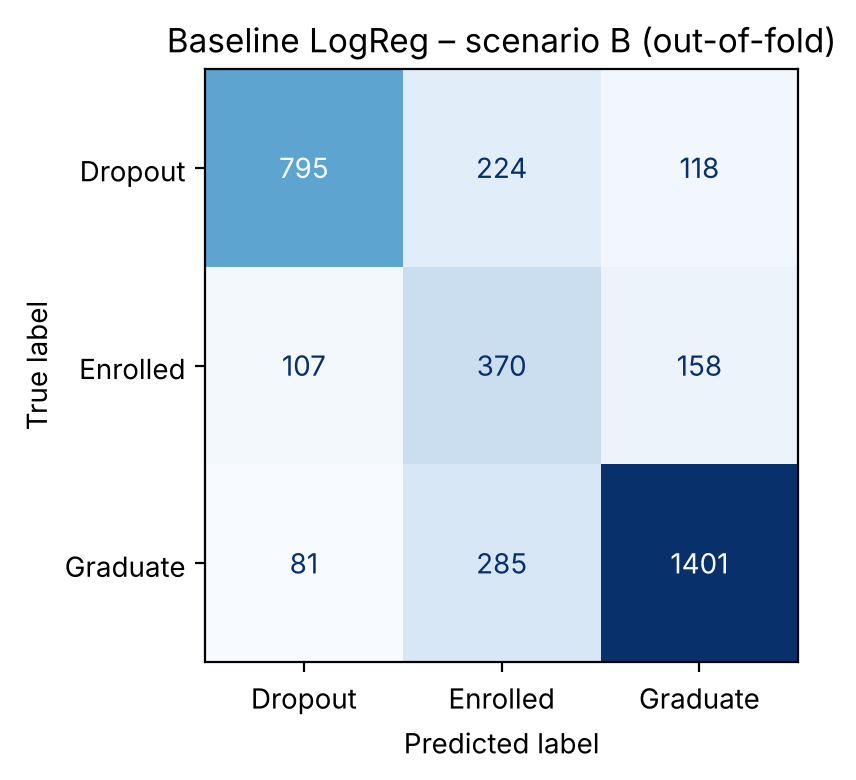

In [5]:
oof=cross_val_predict(pipe,X,y,cv=StratifiedKFold(5,shuffle=True,random_state=SEED),n_jobs=-1)
print(classification_report(y,oof,digits=3))
fig,ax=plt.subplots(figsize=(4.5,4))
ConfusionMatrixDisplay(confusion_matrix(y,oof,labels=CLASSES),display_labels=CLASSES).plot(ax=ax,colorbar=False,cmap="Blues")
ax.set_title("Baseline LogReg – scenario B (out-of-fold)");plt.tight_layout();plt.savefig("../report/figures/confusion_baseline.png",dpi=150);plt.show()

*Enrolled* is the hardest class: it is the minority and sits between the two others (students who are late but still studying).

## 5. Probability calibration
The school will rank students by their dropout probability, so the probabilities must be reliable. We compare out-of-fold probabilities with and without class weights.

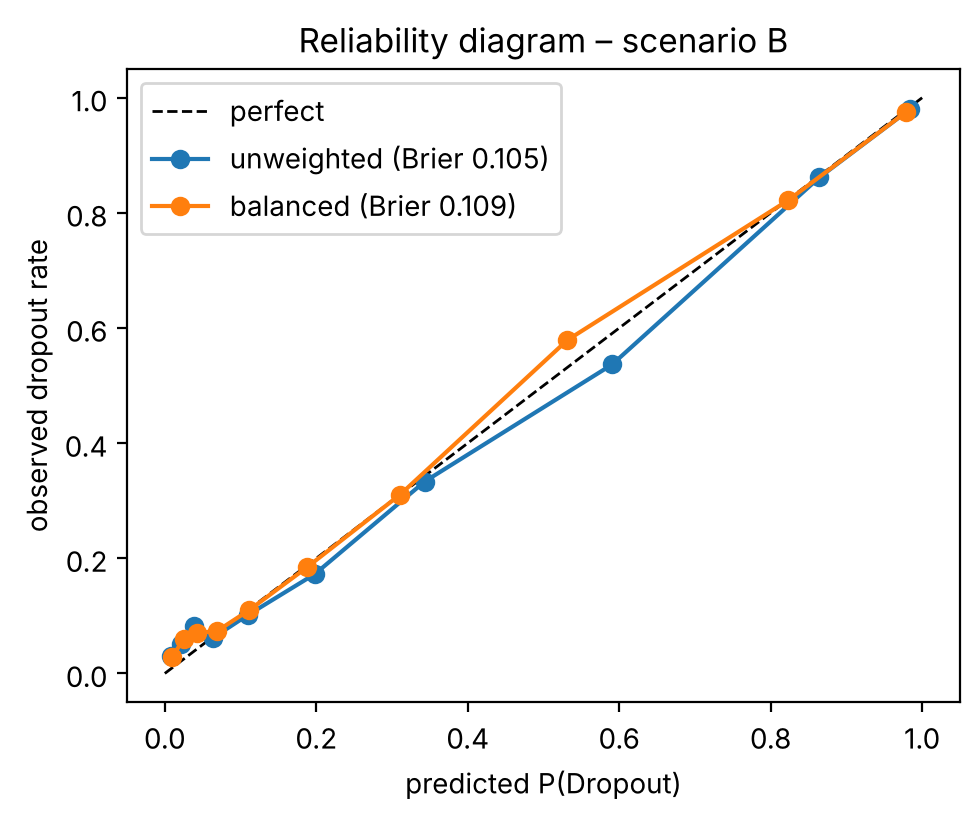

,model,brier,mean predicted,true rate
0,unweighted,0.105,0.322,0.321
1,balanced,0.109,0.309,0.321


In [6]:
fig,ax=plt.subplots(figsize=(5,4.2))
ax.plot([0,1],[0,1],"k--",lw=1,label="perfect")
cal=[]
for name,cw in [("unweighted",None),("balanced",'balanced')]:
    m=Pipeline([("prep",preprocessor(s)),("clf",LogisticRegression(max_iter=3000,class_weight=cw))])
    p=cross_val_predict(m,X,y,cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method="predict_proba",n_jobs=-1)[:,0]
    yt=(y=="Dropout").astype(int)
    fp,mp=calibration_curve(yt,p,n_bins=10,strategy="quantile")
    ax.plot(mp,fp,"o-",label=f"{name} (Brier {brier_score_loss(yt,p):.3f})")
    cal.append({"model":name,"brier":brier_score_loss(yt,p),"mean predicted":p.mean(),"true rate":yt.mean()})
ax.set_xlabel("predicted P(Dropout)");ax.set_ylabel("observed dropout rate");ax.legend();ax.set_title("Reliability diagram – scenario B")
plt.tight_layout();plt.savefig("../report/figures/calibration.png",dpi=150);plt.show()
pd.DataFrame(cal).round(3)

Both models give well-calibrated dropout probabilities (mean predicted ≈ observed rate 0.32, Brier ≈ 0.11); class weights degrade the Brier score slightly. The baseline probabilities can therefore be used to rank students by risk, and the decision threshold will be tuned separately (week 3) to reach the dropout recall target.

## 6. Sensitivity: financial variables in scenario A
`tuition_fees_up_to_date` and `debtor` may be recorded after enrollment. We measure how much scenario A depends on them.

In [7]:
s="A_enrollment";X,y=split_xy(tr,s);rows=[]
for drop in [[],["tuition_fees_up_to_date","debtor"]]:
    pre=preprocessor(s);pre.transformers=[(n,t,[c for c in cols if c not in drop]) for n,t,cols in pre.transformers]
    r=cross_validate(Pipeline([("prep",pre),("clf",LogisticRegression(max_iter=3000,class_weight="balanced"))]),X,y,cv=cv,scoring=SCORING,n_jobs=-1)
    rows.append({"removed":", ".join(drop) or "none",**{m:r[f"test_{m}"].mean() for m in ["macro_f1","dropout_recall","roc_auc_ovr"]}})
pd.DataFrame(rows).round(3)

,removed,macro_f1,dropout_recall,roc_auc_ovr
0,none,0.573,0.590,0.773
1,"tuition_fees_up_to_date, debtor",0.537,0.547,0.737


Removing the two financial flags costs about 0.04 macro-F1 at enrollment. We will confirm their recording date with the data documentation before using them in the enrollment scenario.